In [5]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import plotly.express as px
warnings.filterwarnings("ignore")

In [8]:
os.chdir("C:\Abhishek\CRM\Self\Python\handson")

In [9]:
os.getcwd()

'C:\\Abhishek\\CRM\\Self\\Python\\handson'

In [10]:
df1=pd.read_csv("1_EDA.csv")

In [12]:
df1.shape

(156, 15)

In [13]:
df1.isnull().sum()
#RESALE as max null values

# ID         0
manufact     0
model        0
sales        0
resale      36
type         0
price        1
engine_s     0
horsepow     0
wheelbas     0
width        0
length       0
curb_wgt     1
fuel_cap     0
mpg          2
dtype: int64

In [15]:
df1.isnull().sum()*100/len(df1)    #Percentage Value

# ID         0.000000
manufact     0.000000
model        0.000000
sales        0.000000
resale      23.076923
type         0.000000
price        0.641026
engine_s     0.000000
horsepow     0.000000
wheelbas     0.000000
width        0.000000
length       0.000000
curb_wgt     0.641026
fuel_cap     0.000000
mpg          1.282051
dtype: float64

# MCAR Treatment : Missing Completely at Random

In [ ]:
df1['price'].dropna()

<AxesSubplot:xlabel='price', ylabel='Count'>

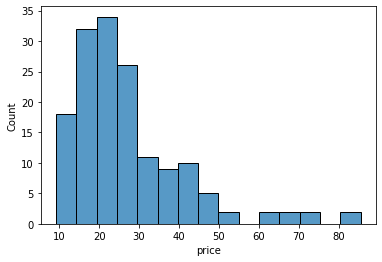

In [16]:
sns.histplot(df1['price'],kde=False)

In [18]:
# As the price data is right skewed, we CANNOT use mean imputation as mean is impacted by skewness, hene we are going to us MEDIAN imputation

df1["price"].fillna(df1["price"].median())

0      21.500
1      28.400
2      22.799
3      42.000
4      23.990
        ...  
151    24.400
152    27.500
153    28.800
154    45.500
155    36.000
Name: price, Length: 156, dtype: float64

In [20]:
df1["price"].isnull().sum()

1

In [21]:
df1["price"].median()

22.799

<AxesSubplot:xlabel='price', ylabel='Count'>

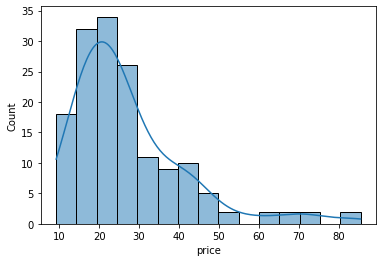

In [24]:
sns.histplot(df1["price"],kde=True)

# Missing Value Treatment for curb_wgt (MCAR)

In [26]:
df1["curb_wgt"].isnull().sum()

1

<AxesSubplot:xlabel='curb_wgt', ylabel='Count'>

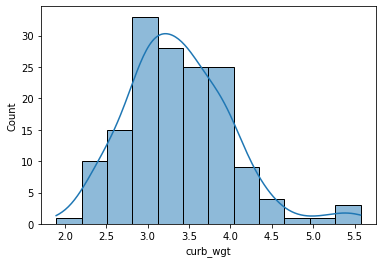

In [27]:
sns.histplot(df1["curb_wgt"],kde=True)

In [ ]:
# it is normal distrubution, hence, can use mean value imputation

In [29]:
curb_wgt_mean=df1["curb_wgt"].mean()
curb_wgt_mean

3.378025806451613

In [33]:
df1["curb_wgt"].fillna(curb_wgt_mean).isna().sum()

0

In [32]:
df1["curb_wgt"].isna().sum()

1

# Treatment on the attribute "mpg"

In [34]:
df1["mpg"]

0      28.0
1      25.0
2      26.0
3      22.0
4      27.0
       ... 
151    25.0
152    25.0
153    25.0
154    23.0
155    24.0
Name: mpg, Length: 156, dtype: float64

In [38]:
non_missing_value_mpg = df1["mpg"].dropna() # so 2 null values

In [39]:
len(non_missing_value_mpg)

154

In [41]:
df1["mpg_mv"] = df1["mpg"].apply(lambda x: np.random.choice(non_missing_value_mpg) if pd.isna(x) else x)

In [44]:
df1["mpg_mv"].isna().sum()

0

In [45]:
def random_sample_imputation(df,col_nm):
    non_missing_value = df1[col_nm].dropna()
    df1[col_nm] = df1[col_nm].apply(lambda x: np.random.choice(non_missing_value) if pd.isna(x) else x)

In [46]:
random_sample_imputation(df1,'curb_wgt')

In [47]:
df1["curb_wgt"].isna().sum()

0

# Method II: MNAR treatment  : 1. Arbitrary Value  2. Tail Value Imputation

In [ ]:
#Leverage Ratio = Debt / Actual Reg Capital: forced condition when LR is max or min. Arbitrary value comes from business sense

In [ ]:
arb_value = 50

In [49]:
df1["curb_wgt_mv"] = df1["curb_wgt"].fillna('arb_value')

In [50]:
df1["curb_wgt_mv"].isna().sum()

0

In [ ]:
# Tail Value can be max or min

In [51]:
max1 = df1["curb_wgt"].max() 

In [52]:
df1["curb_wgt_mv2"] =  df1["curb_wgt"].fillna("max1")

In [53]:
df1

,# ID,manufact,model,sales,resale,type,price,engine_s,horsepow,wheelbas,width,length,curb_wgt,fuel_cap,mpg,mpg_mv,curb_wgt_mv,curb_wgt_mv2
0,1,Acura,Integra,16.919,16.360,Automobile,21.50,1.8,140.0,101.2,67.3,172.4,2.639,13.2,28.0,28.0,2.639,2.639
1,2,Acura,TL,39.384,19.875,Automobile,28.40,3.2,225.0,108.1,70.3,192.9,3.517,17.2,25.0,25.0,3.517,3.517
2,3,Acura,CL,14.114,18.225,Automobile,NaN,3.2,225.0,106.9,70.6,192.0,3.470,17.2,26.0,26.0,3.470,3.470
3,4,Acura,RL,8.588,29.725,Automobile,42.00,3.5,210.0,114.6,71.4,196.6,3.850,18.0,22.0,22.0,3.850,3.850
4,5,Audi,A4,20.397,22.255,Automobile,23.99,1.8,150.0,102.6,68.2,178.0,2.998,16.4,27.0,27.0,2.998,2.998
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
151,153,Volvo,V40,3.545,NaN,Automobile,24.40,1.9,160.0,100.5,67.6,176.6,3.042,15.8,25.0,25.0,3.042,3.042
152,154,Volvo,S70,15.245,NaN,Automobile,27.50,2.4,168.0,104.9,69.3,185.9,3.208,17.9,25.0,25.0,3.208,3.208
153,155,Volvo,V70,17.531,NaN,Automobile,28.80,2.4,168.0,104.9,69.3,186.2,3.259,17.9,25.0,25.0,3.259,3.259
154,156,Volvo,C70,3.493,NaN,Automobile,45.50,2.3,236.0,104.9,71.5,185.7,3.601,18.5,23.0,23.0,3.601,3.601


# MAR: KNN & Linear Regression, Missing Indicator 

In [55]:
# KNN Regression

from sklearn.impute import KNNImputer
features = ['resale','price','horsepow'] # These 3 attributes are taken based on their correlation, higher the better 

In [57]:
df_to_impute = df1[features]
df_to_impute

,resale,price,horsepow
0,16.360,21.50,140.0
1,19.875,28.40,225.0
2,18.225,NaN,225.0
3,29.725,42.00,210.0
4,22.255,23.99,150.0
...,...,...,...
151,NaN,24.40,160.0
152,NaN,27.50,168.0
153,NaN,28.80,168.0
154,NaN,45.50,236.0


In [59]:
imputer = KNNImputer(n_neighbors=5)
imputer

KNNImputer()

In [62]:
imputed_data = imputer.fit_transform(df_to_impute)
imputed_data

array([[ 16.36  ,  21.5   , 140.    ],
       [ 19.875 ,  28.4   , 225.    ],
       [ 18.225 ,  26.1018, 225.    ],
       [ 29.725 ,  42.    , 210.    ],
       [ 22.255 ,  23.99  , 150.    ],
       [ 23.555 ,  33.95  , 200.    ],
       [ 39.    ,  62.    , 310.    ],
       [ 15.209 ,  26.99  , 170.    ],
       [ 28.675 ,  33.4   , 193.    ],
       [ 36.125 ,  38.9   , 193.    ],
       [ 12.475 ,  21.975 , 175.    ],
       [ 13.74  ,  25.3   , 240.    ],
       [ 20.19  ,  31.965 , 205.    ],
       [ 13.36  ,  27.885 , 205.    ],
       [ 22.525 ,  39.895 , 275.    ],
       [ 27.1   ,  44.475 , 275.    ],
       [ 25.725 ,  39.665 , 275.    ],
       [ 18.225 ,  31.01  , 200.    ],
       [ 22.083 ,  46.225 , 255.    ],
       [  9.25  ,  13.26  , 115.    ],
       [ 11.225 ,  16.535 , 170.    ],
       [ 10.31  ,  18.89  , 175.    ],
       [ 11.525 ,  19.39  , 180.    ],
       [ 13.025 ,  24.34  , 200.    ],
       [ 36.225 ,  45.705 , 345.    ],
       [  9.125 ,  13.96 

In [63]:
df1['resale_mv'] = imputed_data[:,0] 

In [64]:
df1['resale_mv'].isna().sum() # Objective achieved

0

# Linear Regression

In [72]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

In [73]:
features2 = ['resale','price','horsepow']

In [77]:
df_to_impute2 = df1[features2]
df_to_impute2

,resale,price,horsepow
0,16.360,21.50,140.0
1,19.875,28.40,225.0
2,18.225,NaN,225.0
3,29.725,42.00,210.0
4,22.255,23.99,150.0
...,...,...,...
151,NaN,24.40,160.0
152,NaN,27.50,168.0
153,NaN,28.80,168.0
154,NaN,45.50,236.0


In [81]:
imputer_2 = IterativeImputer()
imputed_mv_2 = imputer_2.fit_transform(df_to_impute2)

In [82]:
df1["resale_mv_2"] = imputed_mv_2[:,1]

In [83]:
df1

,# ID,manufact,model,sales,resale,type,price,engine_s,horsepow,wheelbas,width,length,curb_wgt,fuel_cap,mpg,mpg_mv,curb_wgt_mv,curb_wgt_mv2,resale_mv,resale_mv_2
0,1,Acura,Integra,16.919,16.360,Automobile,21.50,1.8,140.0,101.2,67.3,172.4,2.639,13.2,28.0,28.0,2.639,2.639,16.360,21.500000
1,2,Acura,TL,39.384,19.875,Automobile,28.40,3.2,225.0,108.1,70.3,192.9,3.517,17.2,25.0,25.0,3.517,3.517,19.875,28.400000
2,3,Acura,CL,14.114,18.225,Automobile,NaN,3.2,225.0,106.9,70.6,192.0,3.470,17.2,26.0,26.0,3.470,3.470,18.225,29.013358
3,4,Acura,RL,8.588,29.725,Automobile,42.00,3.5,210.0,114.6,71.4,196.6,3.850,18.0,22.0,22.0,3.850,3.850,29.725,42.000000
4,5,Audi,A4,20.397,22.255,Automobile,23.99,1.8,150.0,102.6,68.2,178.0,2.998,16.4,27.0,27.0,2.998,2.998,22.255,23.990000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
151,153,Volvo,V40,3.545,NaN,Automobile,24.40,1.9,160.0,100.5,67.6,176.6,3.042,15.8,25.0,25.0,3.042,3.042,14.264,24.400000
152,154,Volvo,S70,15.245,NaN,Automobile,27.50,2.4,168.0,104.9,69.3,185.9,3.208,17.9,25.0,25.0,3.208,3.208,15.209,27.500000
153,155,Volvo,V70,17.531,NaN,Automobile,28.80,2.4,168.0,104.9,69.3,186.2,3.259,17.9,25.0,25.0,3.259,3.259,16.621,28.800000
154,156,Volvo,C70,3.493,NaN,Automobile,45.50,2.3,236.0,104.9,71.5,185.7,3.601,18.5,23.0,23.0,3.601,3.601,29.881,45.500000


In [84]:
df1['resale_mv_2'].isna().sum()

0

In [85]:
os.getcwd()

'C:\\Abhishek\\CRM\\Self\\Python\\handson'